# CSE 3521: Milestone 2 | Classical ML (Group Gamma)

**Goal:** Train Multinomial Naive Bayes with Bag of Words and compare it with a majority-class baseline. Report accuracy, precision, recall, F1, a confusion matrix, informative terms, and prediction errors.

**Dataset:** `data/group_sample_seed44.csv` from the Amazon Fine Food Reviews dataset. Seed **44** is the team's sample seed. Do not resample with a different seed.

**Run locally in VS Code:**
1. Open the **cloned repository folder** in VS Code.
2. Save this notebook as `notebooks/classical_models.ipynb`.
3. Put `group_sample_seed44.csv` inside the existing `data/` folder, but **do not commit the CSV**.
4. Create and select a Python virtual environment, install packages, and choose **Run All** in the notebook.
5. The notebook writes its outputs into the cloned repository's `models/` and `report/` folders, regardless of whether VS Code starts the kernel in `notebooks/` or the repository root.






## 1. Import libraries and locate the data

This cell automatically finds the root of your cloned repository from either the repository root or its `notebooks/` folder. It expects `data/group_sample_seed44.csv` in that root.


In [1]:
from pathlib import Path
import html
import re
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             classification_report, confusion_matrix,
                             precision_recall_fscore_support)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline

# VS Code may start the notebook in notebooks/ or at the repository root.
# Walk upward to find the repository's README.md and data/ folder.
ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / 'README.md').is_file() and (p / 'data').is_dir()),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        'Open the cloned cse3521-sentiment repository in VS Code and '
        'save this notebook under notebooks/ before running it.'
    )

DATA_PATH = ROOT / 'data' / 'group_sample_seed44.csv'
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f'Missing {DATA_PATH}. Ask your Data Engineer for the sample or '
        'generate it using data/README.md. Do not commit CSV files to GitHub.'
    )
print('Repository:', ROOT.resolve())
print('Reading:', DATA_PATH.resolve())
raw = pd.read_csv(DATA_PATH)
print('Rows in original sample:', len(raw))
print('Star ratings:', raw['Score'].value_counts().sort_index().to_dict())
if len(raw) != 50_000:
    print('WARNING: Sample is not 50,000 rows. Check with your Data Engineer.')


Repository: C:\Users\benne\cse3521-sentiment
Reading: C:\Users\benne\cse3521-sentiment\data\group_sample_seed44.csv
Rows in original sample: 50000
Star ratings: {1: 4721, 2: 2690, 3: 3803, 4: 7043, 5: 31743}


## 2. Assign sentiment labels and remove duplicate texts

Our project's label scheme is 1–2 stars = **negative**, 4–5 stars = **positive**. Exclude 3-star reviews.

Removing duplicate review texts before splitting prevents identical text from appearing in the training and test sets. Strip HTML and normalize whitespace while keeping negative words such as "not".

In [2]:
def clean_review(value):
    # Keep meaning-carrying words, including negations.
    text = html.unescape(str(value))
    text = re.sub(r'<[^>]*>', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

# Drop reviews with missing text and keep only the four scored classes.
df = raw.dropna(subset=['Text', 'Score']).copy()
df = df[df['Score'].isin([1, 2, 4, 5])].copy()
df['Text'] = df['Text'].map(clean_review)
df = df[df['Text'].str.len() > 0]

before = len(df)
df = df.drop_duplicates(subset=['Text']).copy()
df['Sentiment'] = np.where(df['Score'] <= 2, 'negative', 'positive')

print('Removed duplicate texts:', before - len(df))
print('Usable binary reviews:', len(df))
print(df['Sentiment'].value_counts())
print('Negative share:', round((df['Sentiment'] == 'negative').mean() * 100, 2), '%')


Removed duplicate texts: 3349
Usable binary reviews: 42848
Sentiment
positive    35994
negative     6854
Name: count, dtype: int64
Negative share: 16.0 %


## 3. Shared 80/20 train/test split



In [3]:
X = df['Text']
y = df['Sentiment']

# Confirm this split seed with your Data Engineer before reporting results.
SPLIT_SEED = 44
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SPLIT_SEED, stratify=y
)

print('Training reviews:', len(X_train))
print('Test reviews:', len(X_test))
print('Train distribution:')
print(y_train.value_counts(normalize=True).round(3))


Training reviews: 34278
Test reviews: 8570
Train distribution:
Sentiment
positive    0.84
negative    0.16
Name: proportion, dtype: float64


## 4. Majority-class baseline

This model always predicts the most frequent training label. It shows how well a classifier can score without understanding the review.

In [4]:
baseline = DummyClassifier(strategy='most_frequent')
start = time.perf_counter()
baseline.fit(X_train.to_frame(), y_train)
baseline_train_seconds = time.perf_counter() - start
baseline_predictions = baseline.predict(X_test.to_frame())
print('Majority label:', baseline.classes_[np.argmax(baseline.class_prior_)])
print(classification_report(y_test, baseline_predictions, zero_division=0))


Majority label: positive
              precision    recall  f1-score   support

    negative       0.00      0.00      0.00      1371
    positive       0.84      1.00      0.91      7199

    accuracy                           0.84      8570
   macro avg       0.42      0.50      0.46      8570
weighted avg       0.71      0.84      0.77      8570



## 5. Train and tune Multinomial Naive Bayes

**Bag of Words:** CountVectorizer counts word occurrences, including two-word phrases (bigrams). The `Pipeline` ensures the vocabulary is learned separately within each training fold, preventing information from leaking out of the test set.


In [5]:
pipeline = Pipeline([
    ('bow', CountVectorizer(ngram_range=(1, 2), min_df=2,
                            max_features=50000, lowercase=True)),
    ('nb', MultinomialNB()),
])
search = GridSearchCV(
    estimator=pipeline,
    param_grid={'nb__alpha': [0.1, 0.5, 1.0, 2.0]},
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=44),
    scoring='f1_macro',
    n_jobs=1,  # Avoid excessive memory usage on laptops.
    refit=True,
)
start = time.perf_counter()
search.fit(X_train, y_train)
nb_train_seconds = time.perf_counter() - start
best_model = search.best_estimator_
nb_predictions = best_model.predict(X_test)

print('Best alpha:', search.best_params_['nb__alpha'])
print('CV macro F1:', round(search.best_score_, 4))
print('Training + tuning time (seconds):', round(nb_train_seconds, 2))
print('Vocabulary size:', len(best_model.named_steps['bow'].vocabulary_))


Best alpha: 0.5
CV macro F1: 0.858
Training + tuning time (seconds): 64.71
Vocabulary size: 50000


## 6. Compare metrics on held-out test data

Include accuracy, precision, recall, and F1. Macro averages give the positive and negative classes equal weight. Also report the **negative-class** recall and F1 because missed negative reviews matter to our use case.

In [6]:
def metrics_row(name, truth, predictions, seconds):
    precision, recall, f1, _ = precision_recall_fscore_support(
        truth, predictions, average='macro', zero_division=0
    )
    neg_p, neg_r, neg_f1, _ = precision_recall_fscore_support(
        truth, predictions, labels=['negative'], average=None, zero_division=0
    )
    return {
        'Model': name,
        'Accuracy': accuracy_score(truth, predictions),
        'Precision (macro)': precision,
        'Recall (macro)': recall,
        'F1 (macro)': f1,
        'Negative recall': neg_r[0],
        'Negative F1': neg_f1[0],
        'Training seconds': seconds,
    }

results = pd.DataFrame([
    metrics_row('Majority-class baseline', y_test, baseline_predictions, baseline_train_seconds),
    metrics_row('Multinomial Naive Bayes (BoW)', y_test, nb_predictions, nb_train_seconds),
])
print(results.round(4).to_string(index=False))
print('\nNAIVE BAYES: detailed classification report')
print(classification_report(y_test, nb_predictions, zero_division=0))


                        Model  Accuracy  Precision (macro)  Recall (macro)  F1 (macro)  Negative recall  Negative F1  Training seconds
      Majority-class baseline    0.8400             0.4200          0.5000      0.4565           0.0000       0.0000            0.0178
Multinomial Naive Bayes (BoW)    0.9177             0.8397          0.8695      0.8535           0.7987       0.7565           64.7102

NAIVE BAYES: detailed classification report
              precision    recall  f1-score   support

    negative       0.72      0.80      0.76      1371
    positive       0.96      0.94      0.95      7199

    accuracy                           0.92      8570
   macro avg       0.84      0.87      0.85      8570
weighted avg       0.92      0.92      0.92      8570



## 7. Create the confusion matrix

Rows are the actual labels. Columns are the predicted labels. 

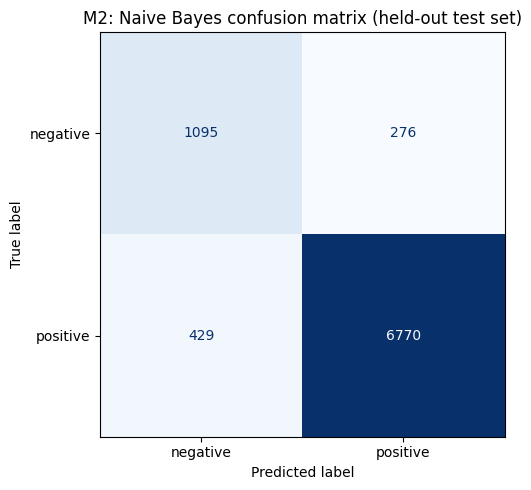

Saved: c:\Users\benne\cse3521-sentiment\report\figures\m2_nb_confusion_matrix.png


In [7]:
labels = ['negative', 'positive']
cm = confusion_matrix(y_test, nb_predictions, labels=labels)
display = ConfusionMatrixDisplay(cm, display_labels=labels)
fig, ax = plt.subplots(figsize=(6, 5))
display.plot(ax=ax, cmap='Blues', values_format='d', colorbar=False)
ax.set_title('M2: Naive Bayes confusion matrix (held-out test set)')
fig.tight_layout()

figures_dir = ROOT / 'report' / 'figures'
figures_dir.mkdir(parents=True, exist_ok=True)
plot_path = figures_dir / 'm2_nb_confusion_matrix.png'
fig.savefig(plot_path, dpi=170, bbox_inches='tight')
plt.show()
print('Saved:', plot_path)


## 8. Top 10 positive and negative phrases



In [8]:
vectorizer = best_model.named_steps['bow']
classifier = best_model.named_steps['nb']
terms = np.array(vectorizer.get_feature_names_out())
classes = list(classifier.classes_)
positive_idx = classes.index('positive')
negative_idx = classes.index('negative')
log_difference = (classifier.feature_log_prob_[positive_idx]
                  - classifier.feature_log_prob_[negative_idx])

pos_terms = terms[np.argsort(log_difference)[-10:][::-1]]
neg_terms = terms[np.argsort(log_difference)[:10]]
print('Top 10 terms associated with POSITIVE sentiment:')
print(', '.join(pos_terms))
print('\nTop 10 terms associated with NEGATIVE sentiment:')
print(', '.join(neg_terms))


Top 10 terms associated with POSITIVE sentiment:
very fresh, can beat, also great, best ve, best coffee, not overpowering, flavorful and, snack or, yum yum, great too

Top 10 terms associated with NEGATIVE sentiment:
false advertising, what disappointment, never purchase, zero stars, threw away, cannot return, and unpleasant, huge disappointment, two stars, emerald forest


## 9. Review 10 misclassified examples



In [9]:
checks = pd.DataFrame({
    'Review': X_test.to_numpy(),
    'Actual': y_test.to_numpy(),
    'Predicted': nb_predictions,
})
wrong = checks[checks['Actual'] != checks['Predicted']]
examples = wrong.sample(n=min(10, len(wrong)), random_state=44) if len(wrong) else wrong
print('Number of mistakes on the test set:', len(wrong))
if examples.empty:
    print('No misclassified examples found.')
else:
    for i, (_, row) in enumerate(examples.iterrows(), start=1):
        print(f'\n{i}. Actual: {row["Actual"]}, Predicted: {row["Predicted"]}')
        print(row['Review'][:500].replace('\n', ' '))


Number of mistakes on the test set: 705

1. Actual: positive, Predicted: negative
After trying other methods without success, I bought these traps based on Amazon's customer reviews and the price. I noticed new gopher mounds on Friday afternoon. On Sunday morning I dug a 12" x 12" hole about 8" deep, between the mounds, and found one tunnel and set the trap in the tunnel per the instructions and without any bait. I tied the trap to a stake and covered the 8" deep hole with a piece of particle board. Seven hours later I checked under the particle board and there was a dead gop

2. Actual: negative, Predicted: positive
Tortilla Land added sugar to their tortillas recently. With obesity and diabetes on the rise in this country, I am disappointed Tortilla Land would add sugar to their tortillas. Tortilla Land can no longer claim their tortillas are healthy. Tortilla Land have integrity and get rid of the sugar.

3. Actual: negative, Predicted: positive
I don't have any dietary restrictions

## 10. Save the model and a Markdown results summary

The saved `.joblib` pipeline includes text preprocessing from CountVectorizer and the trained Naive Bayes classifier. Keep a copy for Milestone 3's Streamlit app. The results Markdown includes numbers but **you must add your own interpretation and error analysis**.

In [ ]:
models_dir = ROOT / 'models'
report_dir = ROOT / 'report'
models_dir.mkdir(parents=True, exist_ok=True)
report_dir.mkdir(parents=True, exist_ok=True)

model_path = models_dir / 'naive_bayes_bow.joblib'
joblib.dump(best_model, model_path)

rounded = results.copy()
for column in rounded.columns:
    if column != 'Model':
        rounded[column] = rounded[column].map(lambda v: f'{v:.4f}' if column != 'Training seconds' else f'{v:.2f}')

headers = list(rounded.columns)
md_table = '| ' + ' | '.join(headers) + ' |\n'
md_table += '| ' + ' | '.join(['---'] * len(headers)) + ' |\n'
for _, row in rounded.iterrows():
    md_table += '| ' + ' | '.join(str(row[col]) for col in headers) + ' |\n'

summary = (
    '# Milestone 2: Classical ML Results (Group Gamma)\n\n'
    'Dataset: Group Gamma 50,000-review sample, random seed 44.\n\n'
    f'Usable binary reviews after filtering and deduplication: {len(df)}. '
    f'Training set: {len(X_train)}. Test set: {len(X_test)}.\n\n'
    'Labels: 1-2 stars = negative, 4-5 stars = positive. 3-star reviews excluded.\n\n'
    f'Split: 80/20 stratified, split seed {SPLIT_SEED}.\n\n'
    'Features: Bag of Words unigrams and bigrams, up to 50,000 vocabulary terms.\n\n'
    f'Best Naive Bayes alpha: {search.best_params_["nb__alpha"]}. '
    f'Cross-validation macro F1: {search.best_score_:.4f}.\n\n'
    '## Test metrics\n\n' + md_table + '\n'
    '## Confusion matrix\n\n'
    '![NB confusion matrix](figures/m2_nb_confusion_matrix.png)\n\n'
    '## Informative terms\n\n'
    '**Positive:** ' + ', '.join(pos_terms) + '\n\n'
    '**Negative:** ' + ', '.join(neg_terms) + '\n\n'
    '## Error analysis (complete in your own words)\n\n'
    'Describe 5-10 mistakes from the notebook. Note recurring patterns and ways to improve.\n\n'
    '## Interpretation (complete in your own words)\n\n'
    'Explain whether Naive Bayes beats the majority-class baseline, especially for negative recall and F1.\n'
)
summary_path = report_dir / 'M2_NB_results.md'
summary_path.write_text(summary, encoding='utf-8')

print('Saved model:', model_path)
print('Saved results summary:', summary_path)
print('Saved confusion matrix:', plot_path)
print('No files have been uploaded to GitHub.')
